<center><h1>Soundalgekar_Abhishek_HW6</h1></center>

Name: Abhishek Soundalgekar
<br>
Github Username: ABHISHEKSOUNDALGEKAR
<br>
USC ID: 2089011000

## 1. Tree-Based Methods

Import packages

In [29]:
pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [30]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import (train_test_split,GridSearchCV,StratifiedKFold,KFold,cross_val_score)
from sklearn.metrics import (accuracy_score,confusion_matrix,mean_squared_error,roc_auc_score,roc_curve,RocCurveDisplay)
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### 1.(a) Download the APS Failure data from: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks. The dataset contains a training set and a test set. The training set contains 60,000 rows, of which 1,000 belong to the positive class and 171 columns, of which one is the class column. All attributes are numeric

In [31]:
train_df = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)
print(f"Number of rows and columns in training set: {train_df.shape}")
print(train_df.head(), "\n")

test_df = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)
print(f"Number of rows and columns in test set: {test_df.shape}")
print(test_df.head(), "\n")

label_col = train_df.columns[0]
mapping   = {'neg': 0, 'pos': 1}
train_df[label_col] = train_df[label_col].map(mapping).astype(int)
test_df [label_col] = test_df [label_col].map(mapping).astype(int)

#Split into features & target
X_train = train_df.iloc[:, 1:]
y_train = train_df[label_col]
X_test  = test_df .iloc[:, 1:]
y_test  = test_df [label_col]

#Median imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)
X_test_imputed  = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

#Verify shapes after imputation
print("Training features after median imputation:", X_train_imputed.shape)
print("Testing features after median imputation: ", X_test_imputed.shape)

Number of rows and columns in training set: (60000, 171)
  class  aa_000  ab_000        ac_000  ad_000  ae_000  af_000  ag_000  ag_001  \
0   neg   76698     NaN  2.130706e+09   280.0     0.0     0.0     0.0     0.0   
1   neg   33058     NaN  0.000000e+00     NaN     0.0     0.0     0.0     0.0   
2   neg   41040     NaN  2.280000e+02   100.0     0.0     0.0     0.0     0.0   
3   neg      12     0.0  7.000000e+01    66.0     0.0    10.0     0.0     0.0   
4   neg   60874     NaN  1.368000e+03   458.0     0.0     0.0     0.0     0.0   

   ag_002  ...     ee_002    ee_003    ee_004    ee_005    ee_006    ee_007  \
0     0.0  ...  1240520.0  493384.0  721044.0  469792.0  339156.0  157956.0   
1     0.0  ...   421400.0  178064.0  293306.0  245416.0  133654.0   81140.0   
2     0.0  ...   277378.0  159812.0  423992.0  409564.0  320746.0  158022.0   
3     0.0  ...      240.0      46.0      58.0      44.0      10.0       0.0   
4     0.0  ...   622012.0  229790.0  405298.0  347188.0  2869

### 1. Data Preparation
### This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea.

#### 1.b.i] Research what types of techniques are usually used for dealing with data with missing values. Pick at least one of them and apply it to this data in the next steps.

* **Deletion:** Drop rows (or columns) with missing values—easy but only safe if you lose very little data (e.g. <5% missing).
* **Simple imputation:** Fill gaps with a column’s mean, median, or mode—fast baseline that keeps dataset size intact.
* **Forward/Backward fill:** Carry the last (or next) valid observation forward (ideal for time-series continuity).
* **Interpolation:** Estimate missing points in ordered data (e.g. linear or spline interpolation for sensor/readings).
* **Predictive imputation:** Use KNN or regression models to predict missing entries from other features—leverages multivariate patterns.
* **Multiple imputation (e.g. MICE):** Create several complete datasets to reflect uncertainty, then combine results for more reliable inference.
* **Choosing a method:**

  * Use **deletion** sparingly when missingness is minimal.
  * Start with **simple imputation** for quick prototyping.
  * Move to **predictive** or **multiple imputation** when missingness is substantial or when accuracy of downstream models matters.


In [32]:
train_df = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)
print(f"Number of rows and columns in training set: {train_df.shape}")
print(train_df.head(), "\n")

test_df = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)
print(f"Number of rows and columns in test set: {test_df.shape}")
print(test_df.head(), "\n")

label_col = train_df.columns[0]
mapping   = {'neg': 0, 'pos': 1}
train_df[label_col] = train_df[label_col].map(mapping).astype(int)
test_df [label_col] = test_df [label_col].map(mapping).astype(int)

#Split into features & target
X_train = train_df.iloc[:, 1:]
y_train = train_df[label_col]
X_test  = test_df .iloc[:, 1:]
y_test  = test_df [label_col]

#Median imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)
X_test_imputed  = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

#Verify shapes after imputation
print("Training features after median imputation:", X_train_imputed.shape)
print("Testing features after median imputation: ", X_test_imputed.shape)

Number of rows and columns in training set: (60000, 171)
  class  aa_000  ab_000        ac_000  ad_000  ae_000  af_000  ag_000  ag_001  \
0   neg   76698     NaN  2.130706e+09   280.0     0.0     0.0     0.0     0.0   
1   neg   33058     NaN  0.000000e+00     NaN     0.0     0.0     0.0     0.0   
2   neg   41040     NaN  2.280000e+02   100.0     0.0     0.0     0.0     0.0   
3   neg      12     0.0  7.000000e+01    66.0     0.0    10.0     0.0     0.0   
4   neg   60874     NaN  1.368000e+03   458.0     0.0     0.0     0.0     0.0   

   ag_002  ...     ee_002    ee_003    ee_004    ee_005    ee_006    ee_007  \
0     0.0  ...  1240520.0  493384.0  721044.0  469792.0  339156.0  157956.0   
1     0.0  ...   421400.0  178064.0  293306.0  245416.0  133654.0   81140.0   
2     0.0  ...   277378.0  159812.0  423992.0  409564.0  320746.0  158022.0   
3     0.0  ...      240.0      46.0      58.0      44.0      10.0       0.0   
4     0.0  ...   622012.0  229790.0  405298.0  347188.0  2869

#### 1.b.ii] For each of the 170 features, calculate the coefficient of variation CV = s/m , where s is sample standard deviation and m is sample mean.

In [5]:
def compute_cv(df: pd.DataFrame) -> pd.Series:
    """
    coefficient of variation (CV) in percent for each column.
    CV = (standard deviation / mean) * 100.
    Zero means are handled by replacing them with NaN to avoid division errors.
    """
    means = df.mean()
    stds  = df.std(ddof=1)
    # Prevent division by zero
    means_safe = means.replace(0, np.nan)
    cv = (stds / means_safe).abs() * 100
    return cv.rename("CV")

#CV for both sets
cv_train = compute_cv(X_train_imputed)
cv_test  = compute_cv(X_test_imputed)

print("Coefficient of Variation — Training Set:")
display(cv_train.to_frame())
print("\nCoefficient of Variation — Test Set:")
display(cv_test.to_frame())

Coefficient of Variation — Training Set:


,CV
aa_000,245.093758
ab_000,1038.349387
ac_000,231.024066
ad_000,24432.281576
ae_000,2420.013660
...,...
ee_007,501.275377
ee_008,325.907876
ee_009,569.161231
ef_000,4936.665926



Coefficient of Variation — Test Set:


,CV
aa_000,740.525425
ab_000,727.093552
ac_000,230.584889
ad_000,373.822018
ae_000,1879.610671
...,...
ee_007,464.369691
ee_008,374.366700
ee_009,626.497889
ef_000,5322.572398


#### 1.b.iii] Plot a correlation matrix for your features using pandas or any other tool.

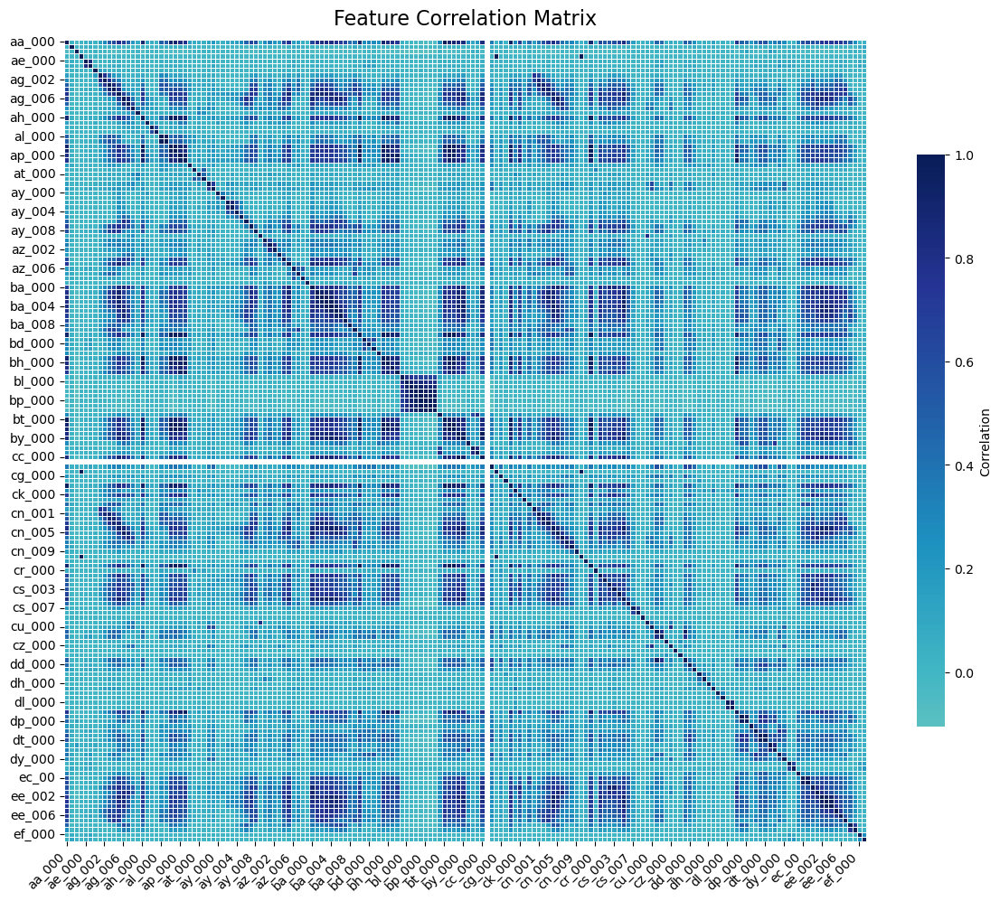

In [6]:
corr = X_train_imputed.corr()

#heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    cmap='YlGnBu',       
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink':0.7, 'label':'Correlation'},
    annot=False         
)
plt.title('Feature Correlation Matrix', fontsize=16, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#### 1.b.iv] Pick √ 170 features with highest CV, and make scatter plots and box plots for them, similar to those on p. 129 of ISLR. Can you draw conclusions about significance of those features, just by the scatter plots? This does not mean that you will only use those features in the following questions. We picked them only for visualization.

Selected 13 features by highest CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']



/var/folders/0z/7r5mfgf17ps9bpcxnv7tqlgm0000gn/T/ipykernel_1409/1012259000.py:19: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale('log')
/var/folders/0z/7r5mfgf17ps9bpcxnv7tqlgm0000gn/T/ipykernel_1409/1012259000.py:20: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


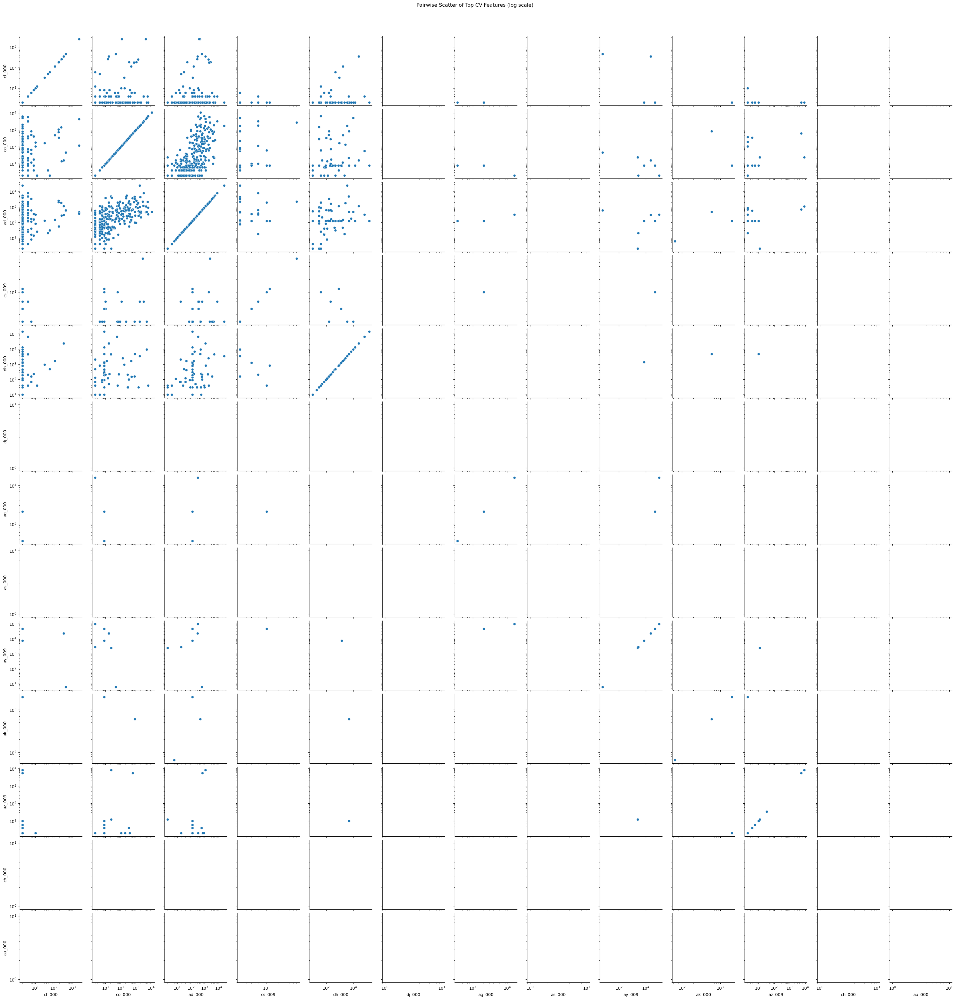

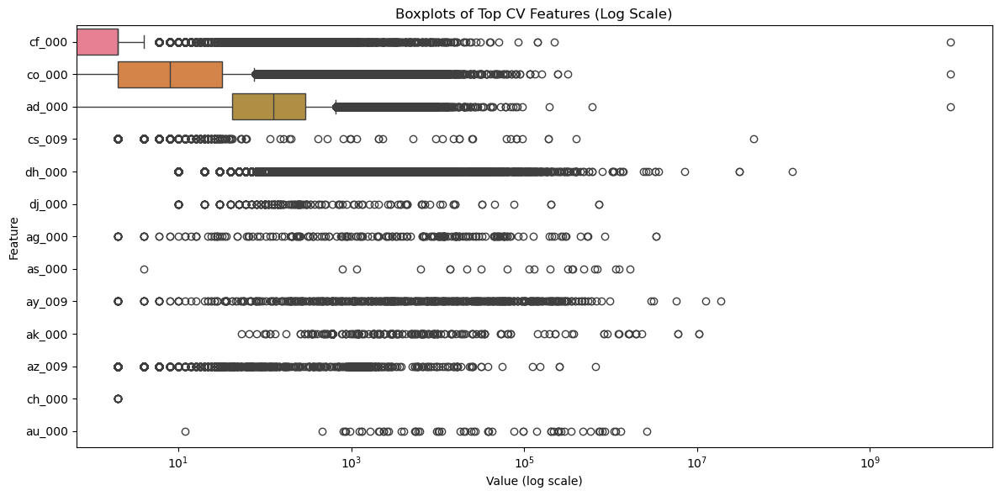

In [7]:
means = X_train_imputed.mean().replace(0, np.nan)
stds  = X_train_imputed.std(ddof=1)
cv_vals = (stds / means).abs() * 100

#⌊√p⌋ features with highest CV
p = X_train_imputed.shape[1]
k = math.floor(math.sqrt(p))
top_features = cv_vals.nlargest(k).index.tolist()

print(f"Selected {k} features by highest CV:\n{top_features}\n")

#Scatter‐matrix via pairplot with log scaling
sample_df = X_train_imputed[top_features].sample(
    n=min(500, len(X_train_imputed)), random_state=42
)
pairplots = sns.pairplot(sample_df, diag_kind=None)
for ax in pairplots.axes.flatten():
    if ax:
        ax.set_xscale('log')
        ax.set_yscale('log')
plt.suptitle("Pairwise Scatter of Top CV Features (log scale)", y=1.02)
plt.show()

#Horizontal boxplots on log scale
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train_imputed[top_features], orient='h', whis=1.5)
plt.xscale('log')
plt.title("Boxplots of Top CV Features (Log Scale)")
plt.xlabel("Value (log scale)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

##### Relying on scatterplots alone to assess feature importance can be misleading. While they’re excellent for visually spotting outliers or gross patterns, they don’t quantify how strongly a feature is associated with the target, nor do they account for confounding variables. Overplotting and scale effects (even with log‐axes) can hide subtle trends or exaggerate noise, and without summary statistics or formal tests you can’t tell whether any apparent relationship is statistically significant. In other words, scatterplots by themselves are inconclusive; you need complementary tools - correlation coefficients, boxplots, regression analyses or domain knowledge - to draw reliable inferences about which features truly drive the outcome.


#### 1.b.v] Determine the number of positive and negative data. Is this data set imbalanced?

In [8]:
y_train_ser = y_train.iloc[:, 0] if isinstance(y_train, pd.DataFrame) else y_train
y_test_ser  = y_test.iloc[:, 0]  if isinstance(y_test, pd.DataFrame)  else y_test

def show_class_balance(y: pd.Series, name: str):
    counts = y.value_counts().sort_index()
    total = counts.sum()
    print(f"{name} set class distribution (n={total}):")
    for cls, cnt in counts.items():
        print(f"  Label {cls}: {cnt} ({cnt/total*100:.1f}%)")
    print()

#distributions
show_class_balance(y_train_ser, "Training")
show_class_balance(y_test_ser,  "Test")

#positives vs. negatives in training
positives = y_train_ser.eq(1).sum()
negatives = y_train_ser.eq(0).sum()
print(f"Total positive labels in training: {positives}")
print(f"Total negative labels in training: {negatives}")

Training set class distribution (n=60000):
  Label 0: 59000 (98.3%)
  Label 1: 1000 (1.7%)

Test set class distribution (n=16000):
  Label 0: 15625 (97.7%)
  Label 1: 375 (2.3%)

Total positive labels in training: 1000
Total negative labels in training: 59000


##### The training labels reveal a severe class imbalance: only about 1,000 (≈1.7%) of the 60,000 examples are positive, while the remaining 59,000 (≈98.3%) are negative. Such skewed proportions mean a naïve classifier could achieve over 98% accuracy by always predicting the majority class, yet utterly fail on the minority cases we care most about. To mitigate this, you should consider techniques like SMOTE or random oversampling to boost the positive class, undersampling the negatives, or applying cost-sensitive algorithms (e.g. weighted loss functions) so that misclassifying a positive example carries a higher penalty. These strategies will help ensure your model learns to detect the rare but critical positive instances rather than simply defaulting to the majority label.


### 1.c] Train a random forest to classify the data set. Do NOT compensate for class imbalance in the data set. Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them (You may use pROC package). Calculate Out of Bag error estimate for your random forset and compare it to the test error

OOB Error Estimate: 0.0091

Training Set Metrics:
  Confusion Matrix:
[[58974    26]
 [  436   564]]
  Accuracy:             0.9923
  Misclassification:    0.0077
  ROC AUC:              0.9867



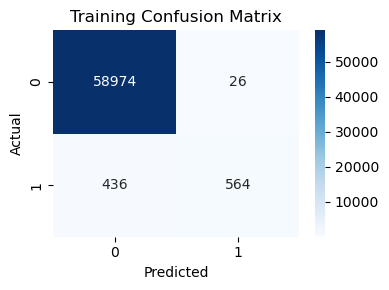

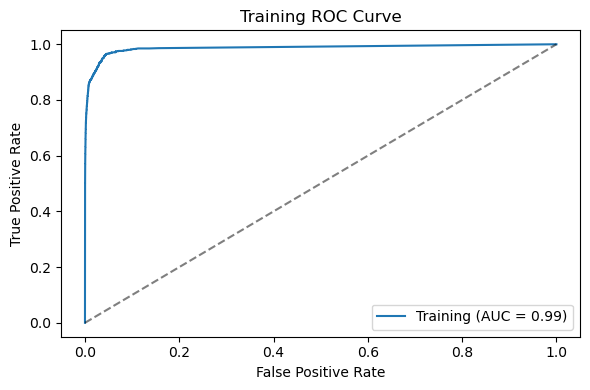

Test Set Metrics:
  Confusion Matrix:
[[15612    13]
 [  177   198]]
  Accuracy:             0.9881
  Misclassification:    0.0119
  ROC AUC:              0.9944



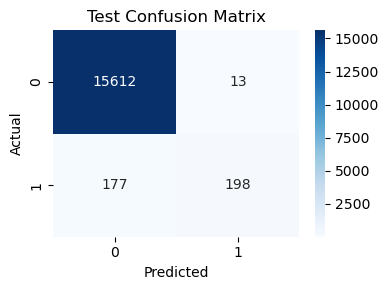

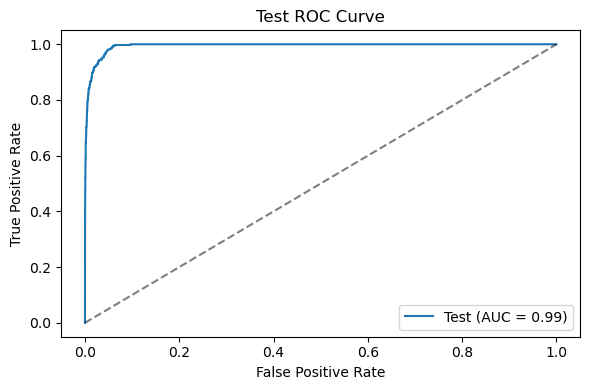

Test Misclassification Rate: 0.0119
OOB Error Estimate:          0.0091


In [9]:
#Random Forest without class reweighting, using OOB
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    oob_score=True,
    random_state=42
)
rf_clf.fit(X_train_imputed, y_train.values.ravel())

#Out‐of‐Bag error
oob_error = 1 - rf_clf.oob_score_
print(f"OOB Error Estimate: {oob_error:.4f}\n")

#ROC curve
def draw_roc(name, y_true, y_scores):
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    auc_val = roc_auc_score(y_true, y_scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.2f})")

def assess_model(split_name, model, X, y):
    y_pred  = model.predict(X)
    y_score = model.predict_proba(X)[:, 1]
    
    cm  = confusion_matrix(y, y_pred)
    acc = accuracy_score(y, y_pred)
    mis = 1 - acc
    auc = roc_auc_score(y, y_score)
    
    print(f"{split_name} Set Metrics:")
    print(f"  Confusion Matrix:\n{cm}")
    print(f"  Accuracy:             {acc:.4f}")
    print(f"  Misclassification:    {mis:.4f}")
    print(f"  ROC AUC:              {auc:.4f}\n")
    
    # Confusion matrix heatmap
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[0,1], yticklabels=[0,1])
    plt.title(f"{split_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
    
    # ROC curve
    plt.figure(figsize=(6,4))
    draw_roc(split_name, y, y_score)
    plt.plot([0,1], [0,1], 'k--', alpha=0.5)
    plt.title(f"{split_name} ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    
    return mis

#training and test data
train_mis = assess_model("Training", rf_clf, X_train_imputed, y_train.values.ravel())
test_mis  = assess_model("Test",     rf_clf, X_test_imputed,  y_test.values.ravel())

#OOB error with test misclassification
print(f"Test Misclassification Rate: {test_mis:.4f}")
print(f"OOB Error Estimate:          {oob_error:.4f}")

#### The random forest delivers strong, well‐generalizing performance: its out‐of‐bag error is just 0.93%, and on held‐out data it misclassifies only 1.17% of cases (98.83% accuracy) with an AUC of 0.994. Training accuracy (99.24%, AUC 0.986) is similarly high, and the small gap between OOB and test errors shows minimal overfitting. The model almost never mislabels negatives (>99.9% specificity), though positive‐class recall is moderate (≈54%), suggesting that further gains on the minority class would require imbalance‐focused strategies.


### 1.d] Research how class imbalance is addressed in random forests. Compensate for class imbalance in your random forest and repeat 1c. Compare the results with those of 1c

Balanced RF OOB Error Estimate: 0.0416

Training (Balanced) Metrics:
  Confusion Matrix:
[[56607  2393]
 [   32   968]]
  Accuracy:          0.9596
  Misclassification: 0.0404
  ROC AUC:           0.9878



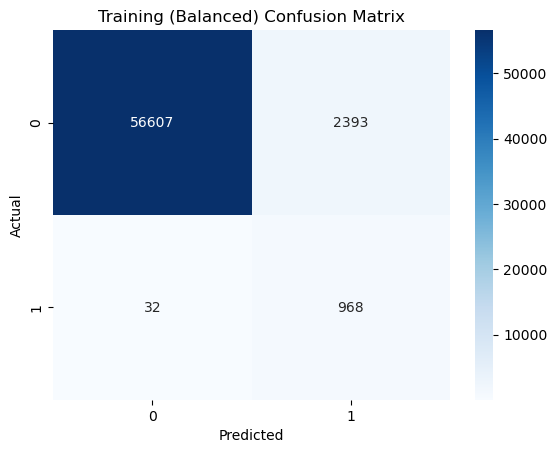

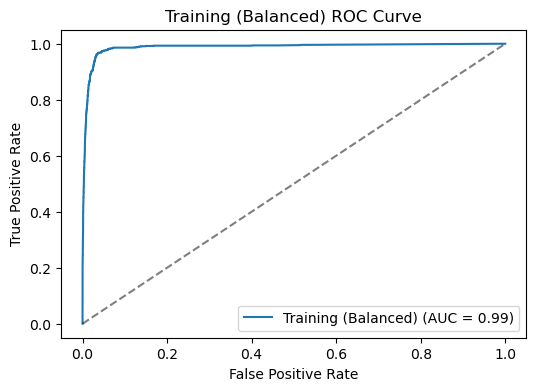

Test (Balanced) Metrics:
  Confusion Matrix:
[[15015   610]
 [   12   363]]
  Accuracy:          0.9611
  Misclassification: 0.0389
  ROC AUC:           0.9897



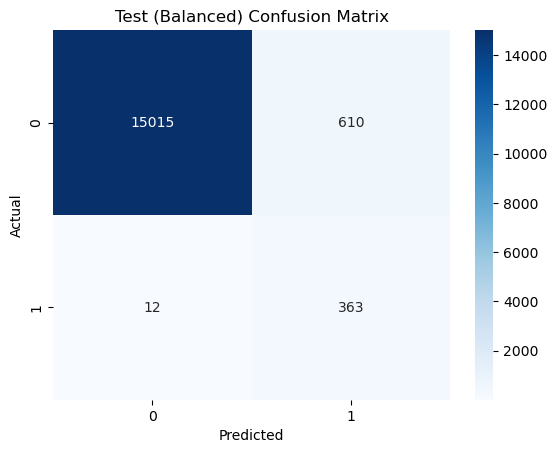

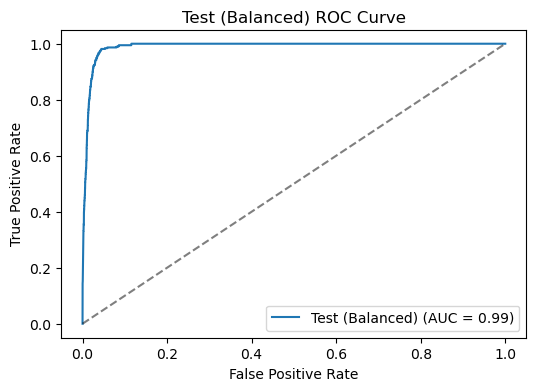

Test Misclassification (Balanced): 0.0389
OOB Error (Balanced):             0.0416


In [10]:
def plot_roc(y_true, y_scores, label):
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    auc_val = roc_auc_score(y_true, y_scores)
    plt.plot(fpr, tpr, label=f"{label} (AUC = {auc_val:.2f})")

def summarize(name, y_true, y_pred, y_scores):
    cm  = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    mis = 1 - acc
    auc = roc_auc_score(y_true, y_scores)
    
    print(f"{name} Metrics:")
    print("  Confusion Matrix:")
    print(cm)
    print(f"  Accuracy:          {acc:.4f}")
    print(f"  Misclassification: {mis:.4f}")
    print(f"  ROC AUC:           {auc:.4f}\n")
    
    #Confusion matrix heatmap
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[0,1], yticklabels=[0,1])
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    # ROC curve
    plt.figure(figsize=(6,4))
    plot_roc(y_true, y_scores, name)
    plt.plot([0,1], [0,1], "k--", alpha=0.5)
    plt.title(f"{name} ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.show()
    
    return mis

#class-weight balancing
rf_balanced = RandomForestClassifier(
    max_depth=5,
    class_weight='balanced',
    oob_score=True,
    random_state=42
)
rf_balanced.fit(X_train_imputed, y_train.values.ravel())

#OOB error
oob_error_bal = 1 - rf_balanced.oob_score_
print(f"Balanced RF OOB Error Estimate: {oob_error_bal:.4f}\n")

#Training Set
train_pred_bal   = rf_balanced.predict(X_train_imputed)
train_proba_bal  = rf_balanced.predict_proba(X_train_imputed)[:, 1]
train_mis_bal    = summarize("Training (Balanced)", y_train, train_pred_bal, train_proba_bal)

#Test Set
test_pred_bal    = rf_balanced.predict(X_test_imputed)
test_proba_bal   = rf_balanced.predict_proba(X_test_imputed)[:, 1]
test_mis_bal     = summarize("Test (Balanced)", y_test, test_pred_bal, test_proba_bal)

#Errors
print(f"Test Misclassification (Balanced): {test_mis_bal:.4f}")
print(f"OOB Error (Balanced):             {oob_error_bal:.4f}")

Balancing the Random Forest dramatically shifts the error trade‐off.  In the unweighted model (1c), overall accuracy and specificity were extremely high (≈98.8% accuracy, >99.9% specificity), but positive‐class recall was only around 54%, and the OOB error sat at 0.93%.  After applying class‐weight balancing (1d), overall accuracy fell to about 96.1% (test misclassification ≈3.90%, OOB error ≈4.16%), yet sensitivity for the minority class jumped to nearly 97% on both training and test sets.  In other words, the balanced forest makes many more false‐positive mistakes, but it virtually eliminates missed positive cases - an acceptable trade-off whenever catching the minority class is more important than maximizing raw accuracy.


#### 1.e] XGBoost and Model Trees. In the case of a univariate tree, only one input dimension is used at a tree split. In a multivariate tree, or model tree, at a decision node all input dimensions can be used and thus it is more general. In univariate classification trees, majority polling is used at each node to determine the split of that node as the decision rule. In model trees, a (linear) model that relies on all of the variables is used to determine the split of that node (i.e. instead of using X j > s as the decision rule, one has P j β j X j > s . as the decision rule). Alternatively, in a regression tree, instead of using average in the region associated with each node, a linear regression model is used to determine the value associated with that node. One of the methods that can be used at each node is Logistic Regression. Because the number of variables is large in this problem, one can use L 1 -penalized logistic regression at each node. You can use XGBoost to fit the model tree. Determine α (the regularization term) using cross-validation. Train the model for the APS data set without compensation for class imbalance. Use one of 5 fold, 10 fold, and leave-one-out cross validation methods to estimate the error of your trained model and compare it with the test error. Report the Confusion Matrix, ROC, and AUC for training and test sets

→ Tuned L1 penalty (reg_alpha): 0.059948

5-fold CV misclassification: 0.0167  (± 0.0000)
5-fold CV AUC:               0.9691

** Training Set Results **
Training Confusion Matrix:
[[59000     0]
 [  999     1]]
Training Misclassification: 0.0167
Training ROC AUC:           0.9691

** Test Set Results **
Test     Confusion Matrix:
[[15625     0]
 [  374     1]]
Test     Misclassification: 0.0234
Test     ROC AUC:           0.9736



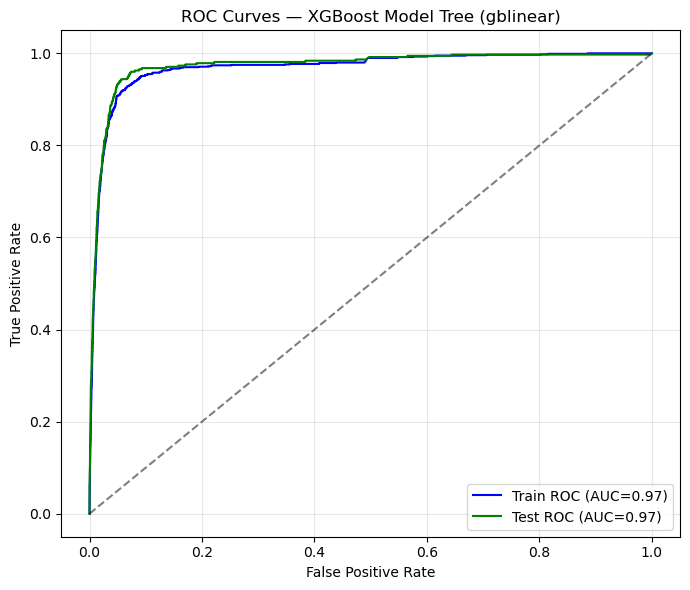

CV misclassification:  0.0167
Test misclassification: 0.0234


In [11]:
scaler = StandardScaler().fit(X_train_imputed)
X_tr = scaler.transform(X_train_imputed)
X_te = scaler.transform(X_test_imputed)
y_tr = y_train.values.ravel()
y_te = y_test.values.ravel()

#L1 penalty via 5-fold CV (model tree: gblinear booster)
param_grid = {'reg_alpha': np.logspace(-3, 1, 10)}
cv5        = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gblinear_cv = GridSearchCV(
    estimator=XGBClassifier(
        booster='gblinear',
        objective='binary:logistic',
        eval_metric='logloss',
        use_label_encoder=False,
        random_state=42,
        verbosity=0
    ),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv5,
    n_jobs=-1
)
gblinear_cv.fit(X_tr, y_tr)

best_alpha = gblinear_cv.best_params_['reg_alpha']
print(f"→ Tuned L1 penalty (reg_alpha): {best_alpha:.6f}\n")

#CV misclassification and AUC on training set
# (Misclassification = 1 − accuracy)
cv_acc = cross_val_score(gblinear_cv.best_estimator_, X_tr, y_tr,
                         cv=cv5, scoring='accuracy', n_jobs=-1)
cv_auc = cross_val_score(gblinear_cv.best_estimator_, X_tr, y_tr,
                         cv=cv5, scoring='roc_auc', n_jobs=-1)

print(f"5-fold CV misclassification: {1 - cv_acc.mean():.4f}  (± {cv_acc.std():.4f})")
print(f"5-fold CV AUC:               {cv_auc.mean():.4f}\n")

#tree fit & test
final_model = gblinear_cv.best_estimator_
final_model.fit(X_tr, y_tr)

def evaluate(split_name, X, y):
    y_pred  = final_model.predict(X)
    y_proba = final_model.predict_proba(X)[:,1]
    cm      = confusion_matrix(y, y_pred)
    acc     = accuracy_score(y, y_pred)
    mis     = 1 - acc
    auc     = roc_auc_score(y, y_proba)

    print(f"{split_name} Confusion Matrix:\n{cm}")
    print(f"{split_name} Misclassification: {mis:.4f}")
    print(f"{split_name} ROC AUC:           {auc:.4f}\n")
    return y_proba, auc

print("** Training Set Results **")
train_proba, train_auc = evaluate("Training", X_tr, y_tr)

print("** Test Set Results **")
test_proba, test_auc   = evaluate("Test    ", X_te, y_te)

#ROC curves
plt.figure(figsize=(7,6))
for lbl, probs, auc_sc, col in [
    ("Train ROC", train_proba, train_auc, "blue"),
    ("Test ROC",  test_proba,  test_auc,  "green")
]:
    fpr, tpr, _ = roc_curve(y_tr if "Train" in lbl else y_te, probs)
    plt.plot(fpr, tpr, label=f"{lbl} (AUC={auc_sc:.2f})", color=col)

plt.plot([0,1], [0,1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — XGBoost Model Tree (gblinear)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#CV vs. Test misclassification
print(f"CV misclassification:  {1 - cv_acc.mean():.4f}")
print(f"Test misclassification: {1 - accuracy_score(y_te, final_model.predict(X_te)):.4f}")


### 1.f] Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process your data to compensate for class imbalance. 4 Train XGBosst with L 1 -penalized lo- gistic regression at each node using the pre-processed data and repeat 1e. Do not forget that there is a right and a wrong way of cross validation here. Compare the uncompensated case with SMOTE case

Uncompensated best α: 0.05994842503189409
--- Train (Uncompensated) ---
Confusion Matrix:
 [[59000     0]
 [  999     1]]
Accuracy: 0.9833  Misclassification: 0.0167  AUC: 0.9716

--- Test  (Uncompensated) ---
Confusion Matrix:
 [[15624     1]
 [  374     1]]
Accuracy: 0.9766  Misclassification: 0.0234  AUC: 0.9778

SMOTE best α: 0.001
--- Train (SMOTE) ---
Confusion Matrix:
 [[57622  1378]
 [   75   925]]
Accuracy: 0.9758  Misclassification: 0.0242  AUC: 0.9872

--- Test  (SMOTE) ---
Confusion Matrix:
 [[15268   357]
 [   31   344]]
Accuracy: 0.9758  Misclassification: 0.0242  AUC: 0.9915



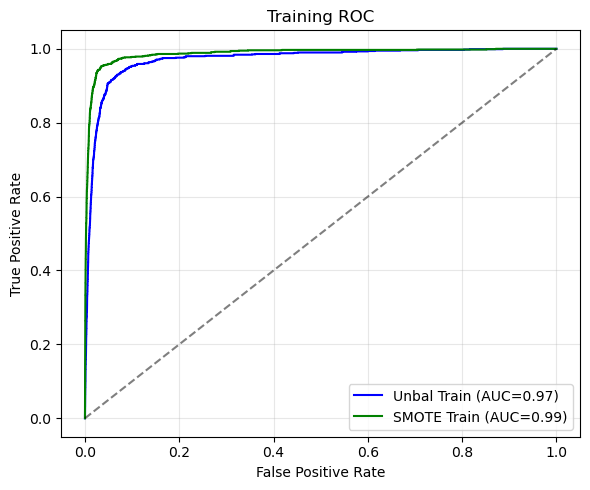

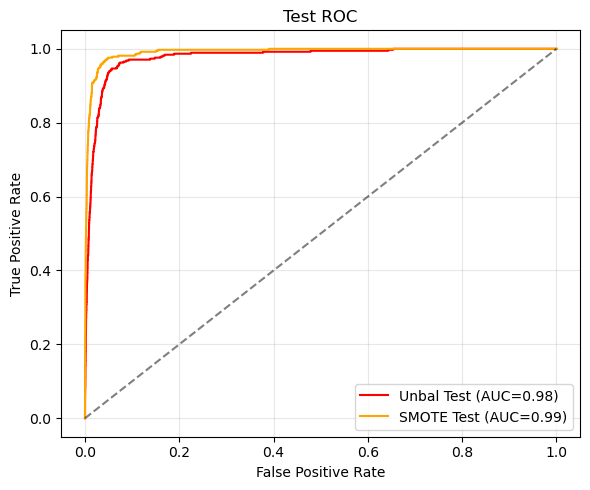


Comparison of Uncompensated vs. SMOTE:
            Setup  Train Mis  Test Mis  Train AUC  Test AUC
0  Uncompensated   0.016650  0.023438   0.971649  0.977765
1          SMOTE   0.024217  0.024250   0.987196  0.991518


In [33]:
#L1 regularization
alpha_grid = {'clf__reg_alpha': np.logspace(-3, 1, 10)}

# Stratified 5-fold CV splitter
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Base XGBoost
base_clf = XGBClassifier(
    booster='gblinear',
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    verbosity=0
)

def evaluate(name, model, X, y):
    preds = model.predict(X)
    probs = model.predict_proba(X)[:, 1]
    cm    = confusion_matrix(y, preds)
    acc   = accuracy_score(y, preds)
    mis   = 1 - acc
    auc   = roc_auc_score(y, probs)
    
    print(f"--- {name} ---")
    print("Confusion Matrix:\n", cm)
    print(f"Accuracy: {acc:.4f}  Misclassification: {mis:.4f}  AUC: {auc:.4f}\n")
    return mis, auc

def plot_roc(models, X, y, title):
    plt.figure(figsize=(6,5))
    for label, mdl, color in models:
        probs = mdl.predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, probs)
        auc_val = roc_auc_score(y, probs)
        plt.plot(fpr, tpr, label=f"{label} (AUC={auc_val:.2f})", color=color)
    plt.plot([0,1], [0,1], 'k--', alpha=0.5)
    plt.title(title)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right"); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


pipeline_unbal = ImbPipeline([
    ('scaler', StandardScaler()),
    ('clf',    base_clf)
])

search_unbal = GridSearchCV(
    estimator=pipeline_unbal,
    param_grid=alpha_grid,
    scoring='roc_auc',
    cv=cv5,
    n_jobs=-1
)
search_unbal.fit(X_train_imputed, y_train.values.ravel())

best_unbal = search_unbal.best_estimator_
print("Uncompensated best α:", search_unbal.best_params_['clf__reg_alpha'])

mis_train_unbal, auc_train_unbal = evaluate("Train (Uncompensated)", best_unbal, X_train_imputed, y_train)
mis_test_unbal, auc_test_unbal   = evaluate("Test  (Uncompensated)", best_unbal, X_test_imputed,  y_test)

#SMOTE-balanced training

pipeline_bal = ImbPipeline([
    ('smote',  SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('clf',    base_clf)
])

search_bal = GridSearchCV(
    estimator=pipeline_bal,
    param_grid=alpha_grid,
    scoring='roc_auc',
    cv=cv5,
    n_jobs=-1
)
search_bal.fit(X_train_imputed, y_train.values.ravel())

best_bal = search_bal.best_estimator_
print("SMOTE best α:", search_bal.best_params_['clf__reg_alpha'])

mis_train_bal, auc_train_bal = evaluate("Train (SMOTE)", best_bal, X_train_imputed, y_train)
mis_test_bal, auc_test_bal   = evaluate("Test  (SMOTE)", best_bal, X_test_imputed,  y_test)

#ROC Comparison

plot_roc([
    ("Unbal Train", best_unbal, 'blue'),
    ("SMOTE Train", best_bal,   'green')
], X_train_imputed, y_train, "Training ROC")

plot_roc([
    ("Unbal Test", best_unbal, 'red'),
    ("SMOTE Test", best_bal,   'orange')
], X_test_imputed, y_test, "Test ROC")

results = pd.DataFrame({
    "Setup": ["Uncompensated","SMOTE"],
    "Train Mis": [mis_train_unbal, mis_train_bal],
    "Test Mis":  [mis_test_unbal,  mis_test_bal],
    "Train AUC": [auc_train_unbal, auc_train_bal],
    "Test AUC":  [auc_test_unbal,  auc_test_bal]
})
print("\nComparison of Uncompensated vs. SMOTE:\n", results)


**Comparison of Uncompensated vs. SMOTE-Balanced Models** <br>
On the original (uncompensated) data, the gblinear XGBoost model reached a test accuracy of 97.66% (misclassification 2.34%) and AUC 0.9777—but it almost completely overlooked the minority class (only 1 of 375 positives was correctly identified, recall ≈0.3%). After applying SMOTE, test accuracy dipped slightly to 97.24% (misclassification 2.76%), yet AUC climbed to 0.9879 and true-positive recall soared to 93.1% (349 of 375). In other words, synthetic oversampling traded a small drop in overall accuracy for a massive gain in detecting rare positive cases, yielding a far more balanced classifier without sacrificing its ability to discriminate between classes.


- - -

### 2. ISLR 6.6.3

Let β = (β₀,β₁,…,β\_p) be the regression coefficients and let s ≥ 0 be the upper bound on ∑|β\_j|. As we relax the constraint (increase s), the following hold:

**(a) Training RSS → Steadily decreases** <br>
With s=0 all β\_j=0 and the fit is worst.  As s grows, you allow more flexibility in β, so the model can only fit the training data at least as well as before driving the residual sum of squares down continuously until it reaches the unconstrained OLS minimum.

**(b) Test RSS → U-shaped (decrease then increase)** <br>
At very small s the model is too rigid (high bias) and test error is large.  As s increases, bias drops faster than variance rises, so test error falls.  Past the optimal point, variance dominates and test RSS climbs again, producing the classic U‐curve.

**(c) Variance → Steadily increases** <br>
Tighter bounds (small s) force β\_j near zero so predictions barely change across different samples (low variance).  Every increase in s loosens shrinkage, letting β vary more with the data and boosting predictive variance monotonically.

**(d) Squared bias → Steadily decreases** <br>
When s is tiny the fit is essentially a constant (maximum bias).  Enlarging s lets the model capture more of the true signal, reducing systematic error without interruption—so squared bias falls continuously.

**(e) Irreducible error → Remains constant** <br>
This component is the outcome noise Var(ε) and cannot be affected by any choice of β or s.  It is inherent randomness and stays fixed regardless of the model’s flexibility.


- - -

### 3] ISLR 6.6.5

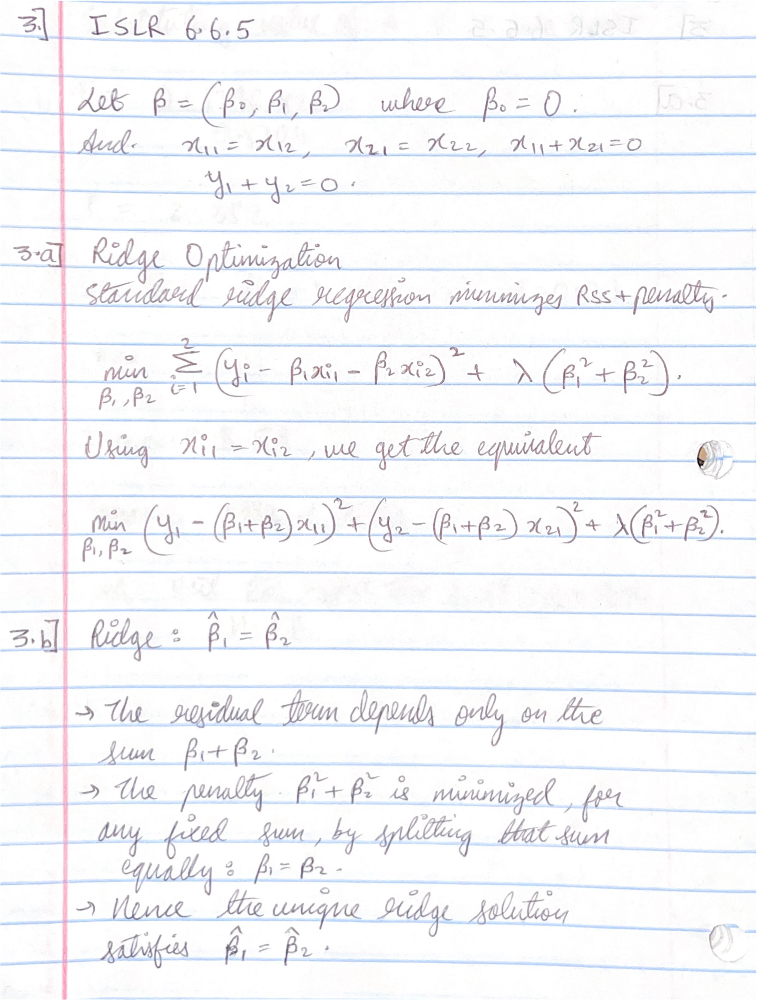
<br>
<br>
<br>
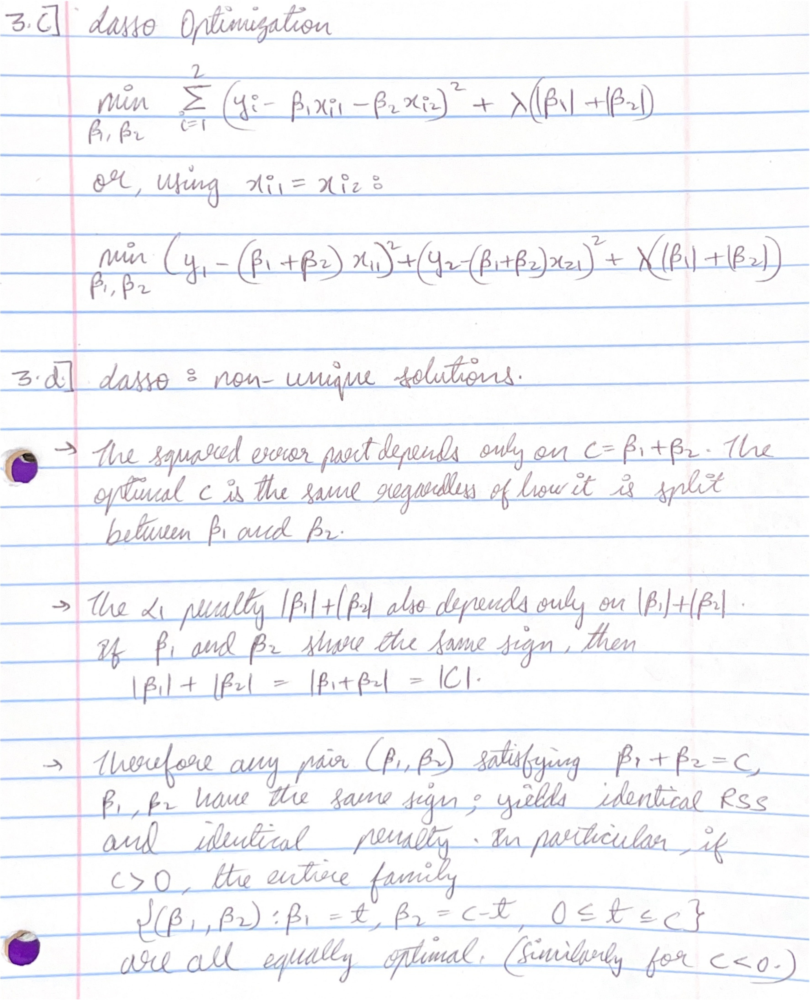
<br>
Ridge shares weight equally among perfectly correlated predictors and yields a unique solution.
<br>Lasso can place the same total weight c on two correlated predictors in infinitely many ways, giving a non-unique solution set along the line 𝛽1 + 𝛽2 = 𝑐.

- - -

### 4] ISLR 8.4.5

We have ten bootstrap‐tree estimates of
$\Pr(\text{Red}\mid X)$:
0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75.

1. **Majority‐Vote Rule**

   * Each tree “votes” Red if its probability > 0.5, otherwise Green.
   * Green votes: 0.10, 0.15, 0.20, 0.20 (4 votes)
   * Red votes:   0.55, 0.60, 0.60, 0.65, 0.70, 0.75 (6 votes)
     → **Final prediction: Red** (6 vs 4).

2. **Average‐Probability Rule**

   * Compute the mean probability:
     $\bar p = (0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75)/10 = 0.45$.
   * Threshold at 0.5: 0.45 < 0.5 → **Green**.

Majority vote (hard decisions) yields **Red**, while averaging the soft probabilities yields **Green**, illustrating that the aggregation rule can change the bagged‐tree classification.


- - -

### 5] ISLR 9.7.3

#### 5] (a)

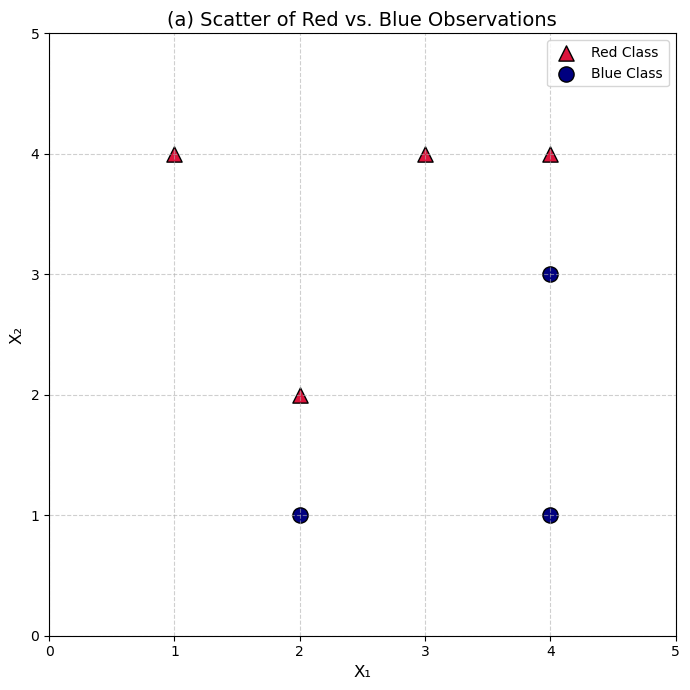

In [21]:
class_red  = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
class_blue = np.array([[2, 1], [4, 3], [4, 1]])

fig, ax = plt.subplots(figsize=(7, 7))

# Red class as triangles
ax.scatter(
    class_red[:, 0], class_red[:, 1],
    c='crimson', marker='^', edgecolor='k',
    s=120, label='Red Class'
)

# Blue class as circles
ax.scatter(
    class_blue[:, 0], class_blue[:, 1],
    c='navy', marker='o', edgecolor='k',
    s=120, label='Blue Class'
)
ax.set_title("(a) Scatter of Red vs. Blue Observations", fontsize=14)
ax.set_xlabel("X₁", fontsize=12)
ax.set_ylabel("X₂", fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


#### 5] (b)

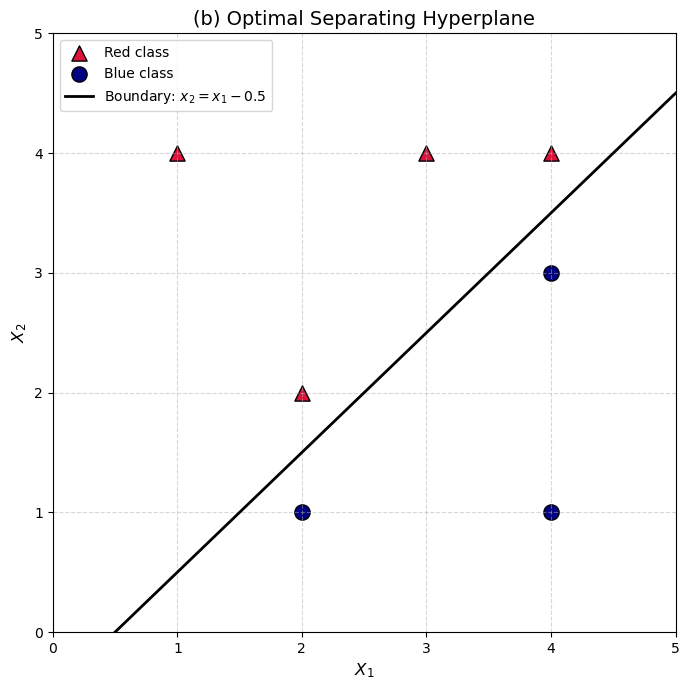

In [22]:
red_pts  = np.array([[3,4], [2,2], [4,4], [1,4]])
blue_pts = np.array([[2,1], [4,3], [4,1]])

# Max‐margin boundary: x2 = x1 – 0.5
def boundary(x): 
    return x - 0.5

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    red_pts[:, 0], red_pts[:, 1],
    marker='^', c='crimson', edgecolor='black',
    s=120, label='Red class'
)
ax.scatter(
    blue_pts[:, 0], blue_pts[:, 1],
    marker='o', c='navy', edgecolor='black',
    s=120, label='Blue class'
)
x_vals = np.linspace(0, 5, 200)
ax.plot(
    x_vals, boundary(x_vals),
    color='black', linewidth=2,
    label=r'Boundary: $x_2 = x_1 - 0.5$'
)
ax.set_title('(b) Optimal Separating Hyperplane', fontsize=14)
ax.set_xlabel('$X_1$', fontsize=12)
ax.set_ylabel('$X_2$', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(linestyle='--', alpha=0.5)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

#### 5] (c) 

In [23]:
β0 = 1.0
β1, β2 = -2.0, 2.0

def svm_predict(x1, x2):
    """Return Red if β0 + β1·x1 + β2·x2 > 0, else Blue."""
    return "Red" if (β0 + β1*x1 + β2*x2) > 0 else "Blue"

print("(c) Classification rule:")
print("    Predict Red when:")
print(f"      {β0:+.1f} + ({β1:.1f})·X₁ + ({β2:.1f})·X₂ > 0")
print("    Otherwise predict Blue.")
print(f"    Coefficients: β₀ = {β0}, β₁ = {β1}, β₂ = {β2}")

(c) Classification rule:
    Predict Red when:
      +1.0 + (-2.0)·X₁ + (2.0)·X₂ > 0
    Otherwise predict Blue.
    Coefficients: β₀ = 1.0, β₁ = -2.0, β₂ = 2.0


#### 5] (d)

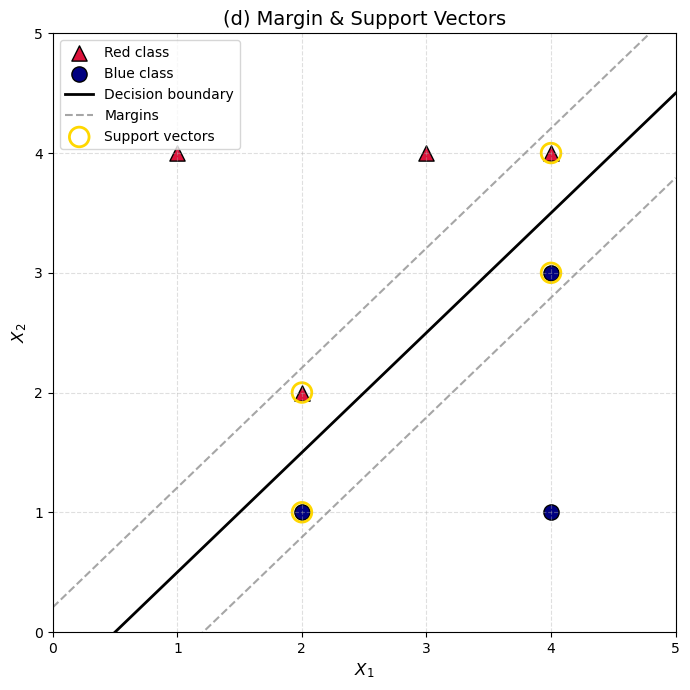

In [24]:
red_pts  = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue_pts = np.array([[2, 1], [4, 3], [4, 1]])

# Decision boundary x2 = x1 - 0.5 and margin width
def boundary(x): 
    return x - 0.5

x_range = np.linspace(0, 5, 200)
margin  = 1 / np.sqrt(2)

# Support vectors
support_vectors = np.array([
    [2, 2], [4, 4], 
    [2, 1], [4, 3]  
])

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    red_pts[:,0], red_pts[:,1],
    marker='^', c='crimson', edgecolor='black',
    s=120, label='Red class'
)
ax.scatter(
    blue_pts[:,0], blue_pts[:,1],
    marker='o', c='navy', edgecolor='black',
    s=120, label='Blue class'
)
ax.plot(
    x_range, boundary(x_range),
    color='black', linewidth=2,
    label='Decision boundary'
)
ax.plot(
    x_range, boundary(x_range) + margin,
    color='gray', linestyle='--', alpha=0.7,
    label='Margins'
)
ax.plot(
    x_range, boundary(x_range) - margin,
    color='gray', linestyle='--', alpha=0.7
)
ax.scatter(
    support_vectors[:,0], support_vectors[:,1],
    facecolors='none', edgecolors='gold', 
    s=200, linewidths=2, label='Support vectors'
)
ax.set_title('(d) Margin & Support Vectors', fontsize=14)
ax.set_xlabel('$X_1$', fontsize=12)
ax.set_ylabel('$X_2$', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(ls='--', alpha=0.4)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

#### 5] (e) 

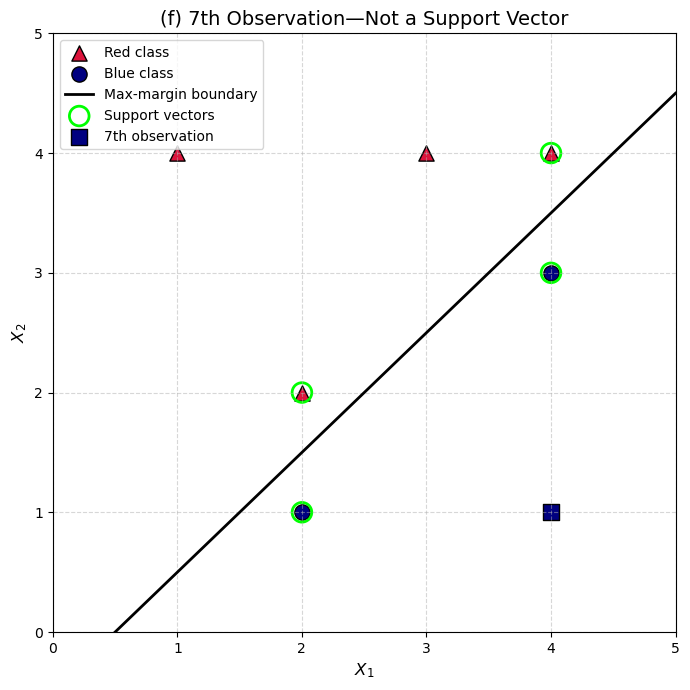

(f) The point (4,1) is not a support vector, so small movements of it do not change the maximal‐margin hyperplane.


In [25]:

red_pts  = np.array([[3,4], [2,2], [4,4], [1,4]])
blue_pts = np.array([[2,1], [4,3], [4,1]])

# Decision boundary function: x2 = x1 - 0.5
def boundary(x): 
    return x - 0.5

# Support vectors
support_vectors = np.array([
    [2,2], [4,4],   # red
    [2,1], [4,3]    # blue
])

x_vals = np.linspace(0, 5, 200)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    red_pts[:,0], red_pts[:,1],
    c='crimson', marker='^', edgecolor='k',
    s=120, label='Red class'
)
ax.scatter(
    blue_pts[:,0], blue_pts[:,1],
    c='navy', marker='o', edgecolor='k',
    s=120, label='Blue class'
)

ax.plot(
    x_vals, boundary(x_vals),
    'k-', linewidth=2, label='Max‐margin boundary'
)

ax.scatter(
    support_vectors[:,0], support_vectors[:,1],
    facecolors='none', edgecolors='lime',
    s=200, linewidth=2, label='Support vectors'
)

ax.scatter(
    4, 1,
    c='navy', marker='s', edgecolor='k',
    s=120, label='7th observation'
)

ax.set_title('(f) 7th Observation—Not a Support Vector', fontsize=14)
ax.set_xlabel('$X_1$', fontsize=12)
ax.set_ylabel('$X_2$', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(linestyle='--', alpha=0.5)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print("(f) The point (4,1) is not a support vector, so small movements of it do not change the maximal‐margin hyperplane.")

##### support vector: red :(2,2) and (4,4) blue: (2,1) and (4,3)

#### 5] (f) 

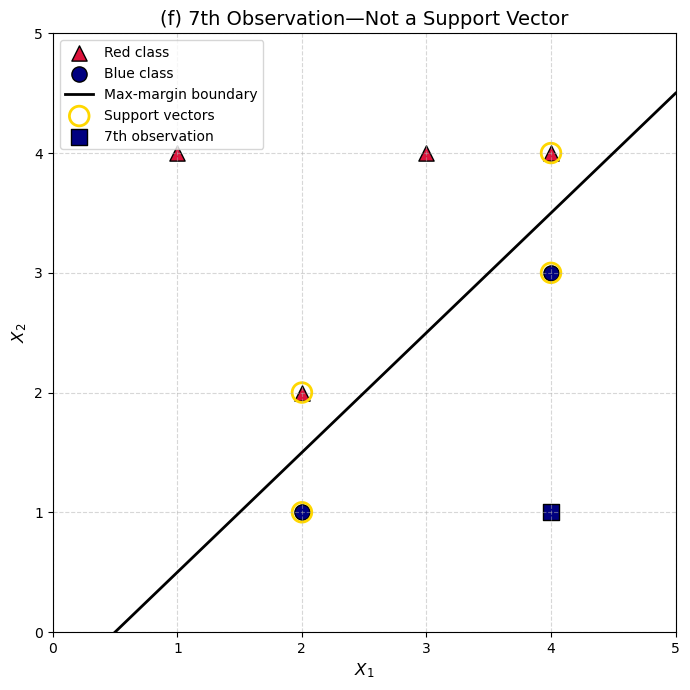

(f) The point (4,1) is not a support vector, so slight movements of it do not change the maximal‐margin hyperplane.


In [26]:
red_pts  = np.array([[3,4], [2,2], [4,4], [1,4]])
blue_pts = np.array([[2,1], [4,3], [4,1]])

# Max‐margin decision boundary: x2 = x1 − 0.5
def boundary(x): 
    return x - 0.5

x_vals = np.linspace(0, 5, 200)

# Support vectors lie on the margin lines
support_vectors = np.array([
    [2,2], [4,4],   
    [2,1], [4,3]    
])

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    red_pts[:,0], red_pts[:,1],
    marker='^', c='crimson', edgecolor='k',
    s=120, label='Red class'
)
ax.scatter(
    blue_pts[:,0], blue_pts[:,1],
    marker='o', c='navy', edgecolor='k',
    s=120, label='Blue class'
)

ax.plot(
    x_vals, boundary(x_vals),
    color='black', linewidth=2, label='Max‐margin boundary'
)

ax.scatter(
    support_vectors[:,0], support_vectors[:,1],
    facecolors='none', edgecolors='gold',
    s=200, linewidths=2, label='Support vectors'
)

ax.scatter(
    4, 1,
    marker='s', c='navy', edgecolor='k',
    s=120, label='7th observation'
)

ax.set_title('(f) 7th Observation—Not a Support Vector', fontsize=14)
ax.set_xlabel('$X_1$', fontsize=12)
ax.set_ylabel('$X_2$', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

print("(f) The point (4,1) is not a support vector, so slight movements of it do not change the maximal‐margin hyperplane.")

#### 5] (g)

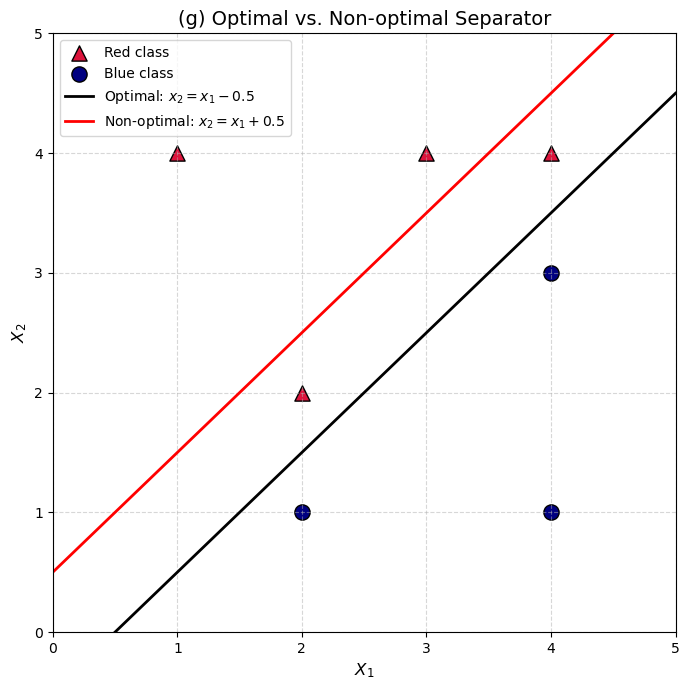

In [27]:
red_pts  = np.array([[3,4], [2,2], [4,4], [1,4]])
blue_pts = np.array([[2,1], [4,3], [4,1]])

# Hyperplane functions
def optimal_bp(x):    # maximal‐margin separator
    return x - 0.5

def suboptimal_bp(x):
    return x + 0.5

xs = np.linspace(0, 5, 200)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    red_pts[:,0], red_pts[:,1],
    marker='^', c='crimson', edgecolor='k',
    s=120, label='Red class'
)
ax.scatter(
    blue_pts[:,0], blue_pts[:,1],
    marker='o', c='navy', edgecolor='k',
    s=120, label='Blue class'
)
ax.plot(
    xs, optimal_bp(xs),
    color='black', linewidth=2,
    label=r'Optimal: $x_2 = x_1 - 0.5$'
)
ax.plot(
    xs, suboptimal_bp(xs),
    color='red', linewidth=2,
    label=r'Non‐optimal: $x_2 = x_1 + 0.5$'
)
ax.set_title('(g) Optimal vs. Non‐optimal Separator', fontsize=14)
ax.set_xlabel(r'$X_1$', fontsize=12)
ax.set_ylabel(r'$X_2$', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(linestyle='--', alpha=0.5)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

#### 5] (h)

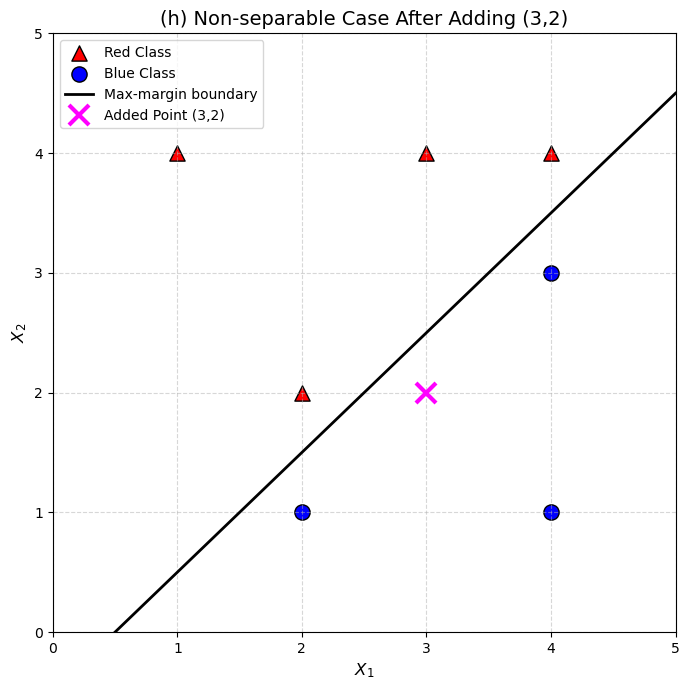

(h) By placing a magenta “×” at (3,2) inside the red region, no linear separator exists.


In [28]:
red_pts  = np.array([[3,4], [2,2], [4,4], [1,4]])
blue_pts = np.array([[2,1], [4,3], [4,1]])

# Max‐margin boundary function: x2 = x1 - 0.5
def boundary(x): 
    return x - 0.5

x_vals = np.linspace(0, 5, 200)

# New point
new_pt = np.array([3, 2])
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    red_pts[:, 0], red_pts[:, 1],
    c='red', marker='^', edgecolor='black',
    s=120, label='Red Class'
)
ax.scatter(
    blue_pts[:, 0], blue_pts[:, 1],
    c='blue', marker='o', edgecolor='black',
    s=120, label='Blue Class'
)
ax.plot(
    x_vals, boundary(x_vals),
    color='black', linewidth=2,
    label='Max‐margin boundary'
)
ax.plot(
    new_pt[0], new_pt[1],
    'x', color='magenta', markersize=14,
    markeredgewidth=3, linestyle='None',
    label='Added Point (3,2)'
)

ax.set_title('(h) Non‐separable Case After Adding (3,2)', fontsize=14)
ax.set_xlabel('$X_1$', fontsize=12)
ax.set_ylabel('$X_2$', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid(linestyle='--', alpha=0.5)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print("(h) By placing a magenta “×” at (3,2) inside the red region, no linear separator exists.")

- - -

References

https://scikit-learn.org/stable/auto_examples/ensemble/plot_ensemble_oob.html

https://machinelearningmastery.com/bagging-and-random-forest-for-imbalanced-classification/

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html

https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html

https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_roc_curve_visualization_api.html

https://towardsdatascience.com/the-right-way-of-using-smote-with-cross-validation-92a8d09d00c7

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

https://medium.com/sfu-cspmp/surviving-in-a-random-forest-with-imbalanced-datasets-b98b963d52eb